# 7a. XRO validation against observations

First of four XRO notebooks (run in order; each also runs on its own from the shared caches):

| Notebook | Question |
| --- | --- |
| **7a_xro_validation** | Is XRO, as configured here, a trustworthy observational benchmark? |
| 7b_xro_events | What does XRO predict for the 2015/16 and 2026/27 El Niños, and from which initial states? |
| 7c_e3sm_xro_state | Where and when do the E3SM hindcasts depart from observations and from XRO? |
| 7d_e3sm_recharge | Do E3SM and XRO differ in recharge-discharge dynamics or in the initial recharge? |

**XRO** (extended nonlinear recharge oscillator; Zhao et al. 2024, *Nature*,
doi:10.1038/s41586-024-07534-6) is fitted to a ten-variable observed state vector: ENSO
[Niño3.4 SST *T*, recharge *h*] plus eight other climate-mode SST indices (NPMM, SPMM, IOB, IOD,
SIOD, TNA, ATL3, SASD; boxes in `util/xro_case.py`). The configuration is the control model of the
paper (annual and semi-annual cycle, quadratic IOD term, *T*² and *Th* terms in the *T* equation),
set once in `xc.XRO_SETUP` for all four notebooks.

**Data.** HadISST 1.1 SST and EN4.2.2 0-700 m heat content, anomalies from their own 1981-2010
monthly climatology. *h* is the 5°S-5°N, 120°E-80°W mean OHC700 (GJ m⁻²), an equatorial Pacific
**OHC700 recharge proxy**, not the 20 °C-isotherm warm-water volume (WWV) of the paper: the hindcasts
save no subsurface temperature. XRO is fitted to detrended anomalies (linear trend for SST, quadratic
for *h*, fitted over the training years only); the trend is added back to forecasts.

**Checks in this notebook (no E3SM data):**

1. Observed state vector and training-period trends, linear vs quadratic for *h*.
2. Fitted recharge-oscillator parameters (growth rate, period) for the two training periods.
3. Intrinsic behaviour: long stochastic simulations against observed seasonal synchronization,
   *h*-leads-*T* lag correlation and persistence.
4. Out-of-sample skill: XRO refitted every year Y on 1981..Y-1 and run from every month of Y
   (1995-2025), against anomaly persistence; linear vs quadratic *h* detrending.
5. Skill by initial month (the months before the Feb/May/Aug/Nov hindcast starts).
6. Amplitude of the DJF peak: does XRO underpredict strong El Niños?
7. Calibration of the stochastic (red-noise) ensemble: spread vs error and 5-95% coverage.

**Lead convention.** In this notebook XRO lead 0 is the initial month (observed); lead *L* verifies
*L* months later. XRO started from the month before a hindcast start has lead 1 = hindcast lead 0.

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from IPython.display import display

from util import rtenso_case as rc
from util import xro_case as xc
from util import pubfig as pf

pf.use_style()

### Run controls

In [2]:
NOTEBOOK = "7a_xro_validation"   # outputs: rc.OUTPUT_ROOT/7a_xro_validation/{figures,data}/
# "auto": reuse valid caches, rebuild stale ones; "rebuild": recompute (e.g. after new observations); "require": fail if missing
derivation_mode = "auto"

# Out-of-sample hindcasts: for each year in VALID["years"], fit on train_start..year-1 and start from every month of year
VALID = {"years": (1995, 2025), "train_start": 1981, "n_month": 24, "ncopy": 50, "seed": 1995}
# Detrending options compared; the first is the control (must match xc.XRO_SETUP["detrend_order"])
TREND_OPTIONS = {"quadratic h": {"default": 1, "WWV": 2}, "linear h": {"default": 1, "WWV": 1}}
CONTROL = next(iter(TREND_OPTIONS))
assert TREND_OPTIONS[CONTROL] == xc.XRO_SETUP["detrend_order"], "first TREND_OPTIONS entry must be the control"
# Stochastic simulations for the intrinsic-behaviour checks
SIM = {"nyear": 100, "ncopy": 50, "seed": 2000}
# Initial months of XRO for the hindcast starts (start month - 1)
START_ICS = {init: xc.add_months(2000, init, -1)[1] for init in (2, 5, 8, 11)}
SKILL_VARS = ["Nino34", "WWV"]
STRONG = 1.5   # observed DJF Niño3.4 (°C) marking a strong El Niño

COLORS = {"XRO": xc.XRO_STYLE["color"], "XRO linear h": "#c77dff", "Persistence": "0.45", "Observed": "k"}
OUTDIR = rc.output_dir(NOTEBOOK, "data")
print("figures ->", rc.figure_dir(NOTEBOOK))

figures -> /global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7a_xro_validation/figures


## 1. Observed state vector and training-period trends

The trend is fitted over each event's training period (1981-2014 for 2015/16, 1981-2025 for
2026/27) and extrapolated. For *h* the control quadratic trend is compared with a linear one: a
quadratic fitted to a short record can bend strongly at its end, which then feeds every forecast.

In [3]:
X = xc.obs_state(mode=derivation_mode)
for var in SKILL_VARS:
    y, m = xc.last_observed(X, var)
    print(f"{xc.short(var)}: {X['time'].values[0].year}-{X['time'].values[0].month:02d} to {y}-{m:02d}")

TRAIN_PERIODS = sorted({event["train"] for event in xc.EVENTS.values()})
FITS = {(train, name): xc.fit_xro(X, train, orders=orders) for train in TRAIN_PERIODS for name, orders in TREND_OPTIONS.items()}

Niño3.4: 1981-01 to 2026-08
h (OHC700): 1981-01 to 2026-07


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7a_xro_validation/figures/fig_xro_obs_state_trends.pdf
/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7a_xro_validation/figures/fig_xro_obs_state_trends.png


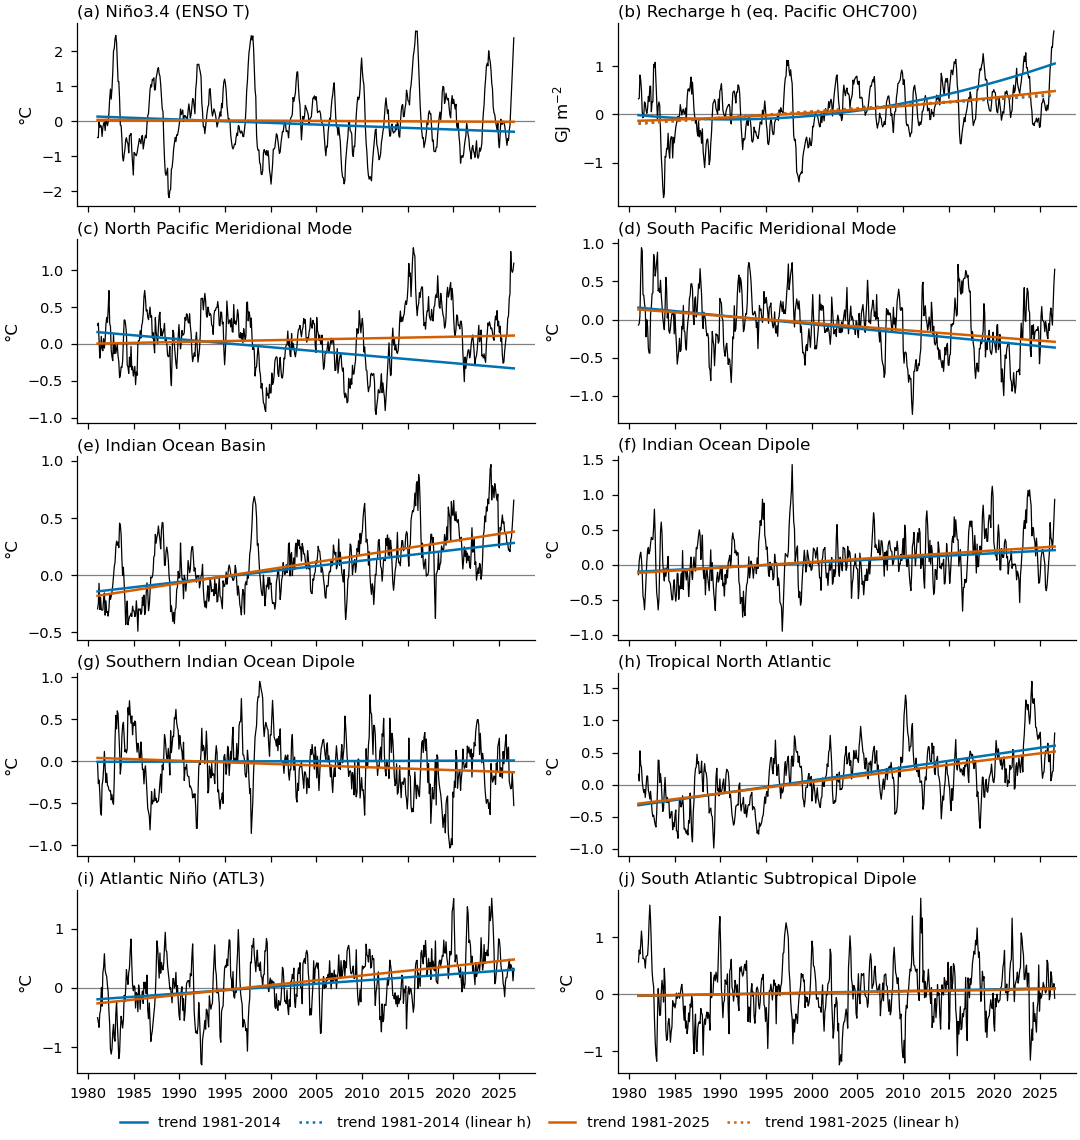

In [4]:
def plot_obs_state():
    fig, axes = plt.subplots(5, 2, figsize=(pf.WIDTH["double"], 7.6), sharex=True)
    t = pd.to_datetime([f"{d.year}-{d.month:02d}-15" for d in X["time"].values])
    train_colors = dict(zip(TRAIN_PERIODS, ["#0072b2", "#d55e00"]))
    for k, (ax, var) in enumerate(zip(axes.flat, xc.XRO_VARS)):
        ax.plot(t, X[var], color="k", lw=0.6)
        for train in TRAIN_PERIODS:
            for name in TREND_OPTIONS:
                if var != "WWV" and name != CONTROL:
                    continue
                tr = xc.trend_values(FITS[(train, name)]["trend"], X["time"].values)[var]
                ax.plot(t, tr, color=train_colors[train], lw=1.2, ls="-" if name == CONTROL else ":",
                        label=f"trend {train[0]}-{train[1]}" + ("" if name == CONTROL else f" ({name})"))
        pf.zero_line(ax)
        pf.panel_label(ax, k, xc.LABELS[var])
        ax.set_ylabel(xc.UNITS[var])
    handles, labels = axes.flat[1].get_legend_handles_labels()
    pf.legend_below(fig, handles, labels, ncol=4)
    return fig


fig = plot_obs_state()
pf.save(fig, NOTEBOOK, "xro", "obs_state_trends")
plt.show()

## 2. Fitted recharge-oscillator parameters

XRO's ENSO block is dT/dt = R T + F₁ h, dh/dt = −F₂ T − ε h (per year), with seasonally varying
coefficients. Its eigenvalues give the growth rate (R − ε)/2 and the period
2π / √(F₁F₂ − ((R + ε)/2)²). F₁ and F₂ carry the units of *h*, so with OHC700 instead of WWV they
differ from the paper's values; their product, and therefore the period, does not. A damped
(negative growth rate) oscillator with a period of a few years is the expected recharge-oscillator
regime; large differences between the two training periods would mean the benchmark is not stable.

,R (1/yr),F1,F2,ε (1/yr),growth (1/yr),period (yr)
1981-2014,-1.03,2.71,0.57,1.39,-1.21,5.11
1981-2025,-1.12,2.66,0.57,1.11,-1.12,5.11


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7a_xro_validation/figures/fig_xro_ro_parameters.pdf
/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7a_xro_validation/figures/fig_xro_ro_parameters.png


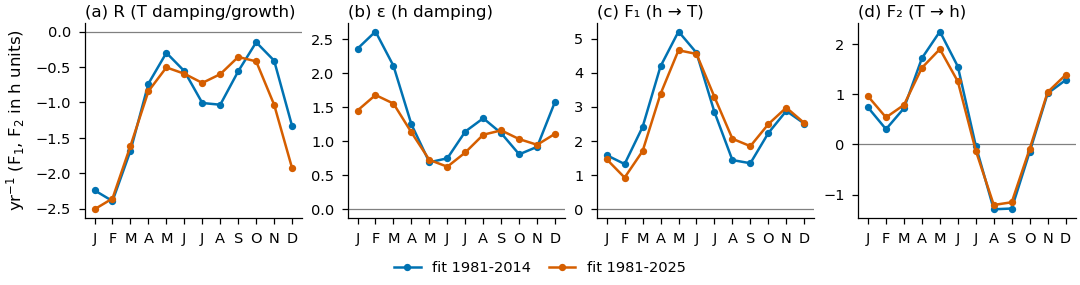

In [5]:
ro = {train: xc.ro_parameters(FITS[(train, CONTROL)]) for train in TRAIN_PERIODS}
ro_table = pd.DataFrame({f"{a}-{b}": ann for (a, b), (_, ann) in ro.items()}).T
ro_table.columns = ["R (1/yr)", "F1", "F2", "ε (1/yr)", "growth (1/yr)", "period (yr)"]
ro_table.round(3).to_csv(OUTDIR / "XRO_RO_parameters_annual_mean.csv")
display(ro_table.round(2))

fig, axes = plt.subplots(1, 4, figsize=(pf.WIDTH["double"], 1.9))
month_letters = list("JFMAMJJASOND")
for train, color in zip(TRAIN_PERIODS, ["#0072b2", "#d55e00"]):
    p, _ = ro[train]
    for k, (ax, key, title) in enumerate(zip(axes, ["R", "epsilon", "F1", "F2"],
                                              ["R (T damping/growth)", "ε (h damping)", "F₁ (h → T)", "F₂ (T → h)"])):
        ax.plot(range(1, 13), p[key], color=color, marker="o", ms=2.5, label=f"fit {train[0]}-{train[1]}")
        pf.panel_label(ax, k, title)
for ax in axes:
    ax.set_xticks(range(1, 13), month_letters)
    pf.zero_line(ax)
axes[0].set_ylabel("yr$^{-1}$ (F$_1$, F$_2$ in h units)")
pf.legend_below(fig, ax=axes[0], ncol=2)
pf.save(fig, NOTEBOOK, "xro", "ro_parameters")
plt.show()

## 3. Intrinsic behaviour: stochastic simulations vs observations

`SIM["ncopy"]` simulations of `SIM["nyear"]` years from each fit, compared with the detrended
observations of the same training years: (a) Niño3.4 standard deviation by calendar month (ENSO
phase-locking to boreal winter), (b) lag correlation of *h*(t) with *T*(t + lag) (recharge leads ENSO
by several months, positive lags), (c) Niño3.4 autocorrelation (persistence and the spring barrier
in the annual mean). Shading is the 5-95% range across simulations; the skewness table checks the
El Niño-La Niña asymmetry that the *T*² and *Th* terms should produce.

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7a_xro_validation/figures/fig_xro_intrinsic_behaviour.pdf
/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7a_xro_validation/figures/fig_xro_intrinsic_behaviour.png


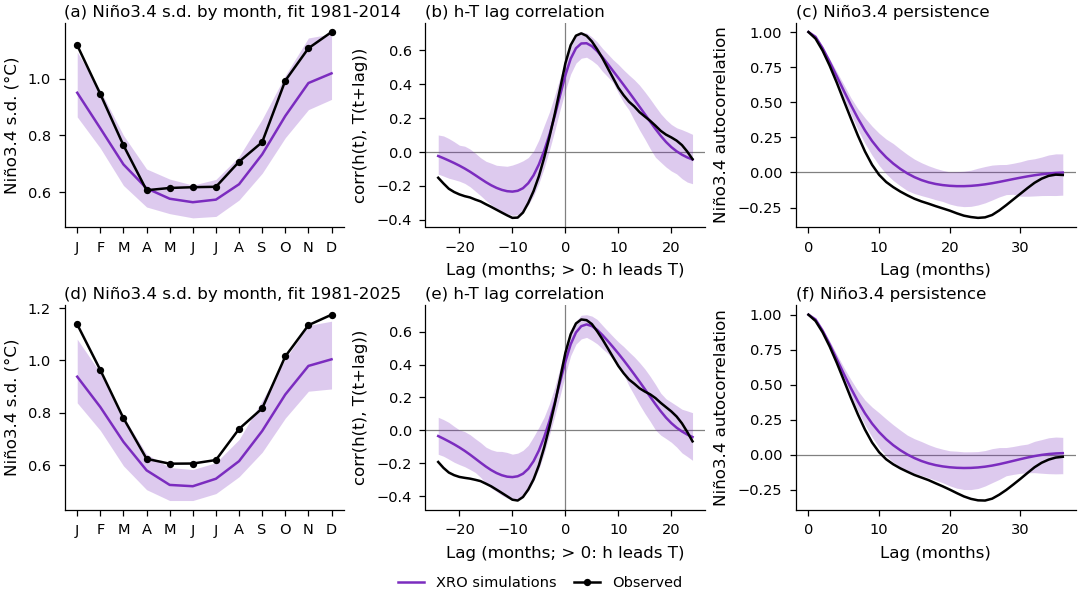

,observed,XRO mean,XRO 5%,XRO 95%
fit,,,,
1981-2014,0.30,0.28,-0.04,0.68
1981-2025,0.48,0.27,-0.06,0.63


In [6]:
def lag_corr(a, b, lags):
    """corr(a(t), b(t + lag)) for each lag."""
    a, b = np.asarray(a, float), np.asarray(b, float)
    out = []
    for L in lags:
        x, y = (a[: len(a) - L], b[L:]) if L >= 0 else (a[-L:], b[: len(b) + L])
        ok = np.isfinite(x) & np.isfinite(y)
        out.append(np.corrcoef(x[ok], y[ok])[0, 1])
    return np.array(out)


def skewness(x):
    x = np.asarray(x, float)
    x = x[np.isfinite(x)] - np.nanmean(x)
    return float(np.mean(x ** 3) / np.mean(x ** 2) ** 1.5)


LAGS = np.arange(-24, 25)
ACF_LAGS = np.arange(0, 37)
fig, axes = plt.subplots(len(TRAIN_PERIODS), 3, figsize=(pf.WIDTH["double"], 2.0 * len(TRAIN_PERIODS)))
skew_rows = []
for r, train in enumerate(TRAIN_PERIODS):
    xf = FITS[(train, CONTROL)]
    obs = xf["X_dt"].sel(time=slice(f"{train[0]}-01", f"{train[1]}-12"))
    sim = xc.simulate(xf, **SIM)
    ax = axes[r, 0]
    sd_sim = sim["Nino34"].groupby("time.month").std("time")
    ax.fill_between(range(1, 13), sd_sim.quantile(0.05, "member"), sd_sim.quantile(0.95, "member"),
                    color=COLORS["XRO"], alpha=0.25, lw=0)
    ax.plot(range(1, 13), sd_sim.mean("member"), color=COLORS["XRO"], label="XRO simulations")
    ax.plot(range(1, 13), obs["Nino34"].groupby("time.month").std("time"), color="k", marker="o", ms=2.5, label="Observed")
    ax.set_xticks(range(1, 13), month_letters)
    ax.set_ylabel("Niño3.4 s.d. (°C)")
    pf.panel_label(ax, 3 * r, f"Niño3.4 s.d. by month, fit {train[0]}-{train[1]}")
    ax = axes[r, 1]
    lc = np.array([lag_corr(sim["WWV"].sel(member=m), sim["Nino34"].sel(member=m), LAGS) for m in sim["member"].values])
    ax.fill_between(LAGS, np.percentile(lc, 5, 0), np.percentile(lc, 95, 0), color=COLORS["XRO"], alpha=0.25, lw=0)
    ax.plot(LAGS, lc.mean(0), color=COLORS["XRO"])
    ax.plot(LAGS, lag_corr(obs["WWV"], obs["Nino34"], LAGS), color="k")
    pf.zero_line(ax)
    pf.zero_line(ax, axis="x")
    ax.set_xlabel("Lag (months; > 0: h leads T)")
    ax.set_ylabel("corr(h(t), T(t+lag))")
    pf.panel_label(ax, 3 * r + 1, "h-T lag correlation")
    ax = axes[r, 2]
    acf = np.array([lag_corr(sim["Nino34"].sel(member=m), sim["Nino34"].sel(member=m), ACF_LAGS) for m in sim["member"].values])
    ax.fill_between(ACF_LAGS, np.percentile(acf, 5, 0), np.percentile(acf, 95, 0), color=COLORS["XRO"], alpha=0.25, lw=0)
    ax.plot(ACF_LAGS, acf.mean(0), color=COLORS["XRO"])
    ax.plot(ACF_LAGS, lag_corr(obs["Nino34"], obs["Nino34"], ACF_LAGS), color="k")
    pf.zero_line(ax)
    ax.set_xlabel("Lag (months)")
    ax.set_ylabel("Niño3.4 autocorrelation")
    pf.panel_label(ax, 3 * r + 2, "Niño3.4 persistence")
    sk = np.array([skewness(sim["Nino34"].sel(member=m)) for m in sim["member"].values])
    skew_rows.append({"fit": f"{train[0]}-{train[1]}", "observed": round(skewness(obs["Nino34"]), 2),
                      "XRO mean": round(float(sk.mean()), 2), "XRO 5%": round(float(np.percentile(sk, 5)), 2),
                      "XRO 95%": round(float(np.percentile(sk, 95)), 2)})
pf.legend_below(fig, ax=axes[0, 0], ncol=2)
pf.save(fig, NOTEBOOK, "xro", "intrinsic_behaviour")
plt.show()
skew = pd.DataFrame(skew_rows).set_index("fit")
skew.to_csv(OUTDIR / "XRO_Nino34_skewness.csv")
display(skew)

## 4. Out-of-sample forecast skill

Each year Y in `VALID["years"]` is forecast by an XRO detrended and fitted on 1981..Y-1 only, from
every observed month of Y, so no forecast has seen its target. Forecasts are verified as full
(not detrended) anomalies, the quantity compared with E3SM later, against anomaly persistence.
Monthly values, no running mean; the verification sample shrinks slightly at long leads near the
end of the record. Cached under `S2D_DIAG_ROOT/observations/xro/`.

In [7]:
%%time
HIND = {}
for name, orders in TREND_OPTIONS.items():
    HIND[name] = xc.rolling_hindcasts(X, VALID["years"], VALID["train_start"], VALID["n_month"], orders=orders,
                                      ncopy=VALID["ncopy"] if name == CONTROL else 0, seed=VALID["seed"],
                                      mode=derivation_mode)
det, stoch = HIND[CONTROL]
OBS_GRID = xc.target_obs(det, X)
print(f"{det.sizes['init']} initial months, {pd.Timestamp(det['init'].values[0]):%Y-%m} to {pd.Timestamp(det['init'].values[-1]):%Y-%m}")

def skill_table(fc, obs):
    return {var: xc.skill(fc[var], obs[var]) for var in SKILL_VARS}


SKILL = {name: skill_table(HIND[name][0], xc.target_obs(HIND[name][0], X)) for name in TREND_OPTIONS}
SKILL["Persistence"] = skill_table(xc.persistence(det, OBS_GRID), OBS_GRID)
obs_sd = {var: float(X[var].sel(time=slice(f"{VALID['years'][0]}-01", None)).std()) for var in SKILL_VARS}

372 initial months, 1995-01 to 2025-12
CPU times: user 976 ms, sys: 84.5 ms, total: 1.06 s
Wall time: 1.11 s


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7a_xro_validation/figures/fig_xro_oos_skill_by_lead.pdf
/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7a_xro_validation/figures/fig_xro_oos_skill_by_lead.png


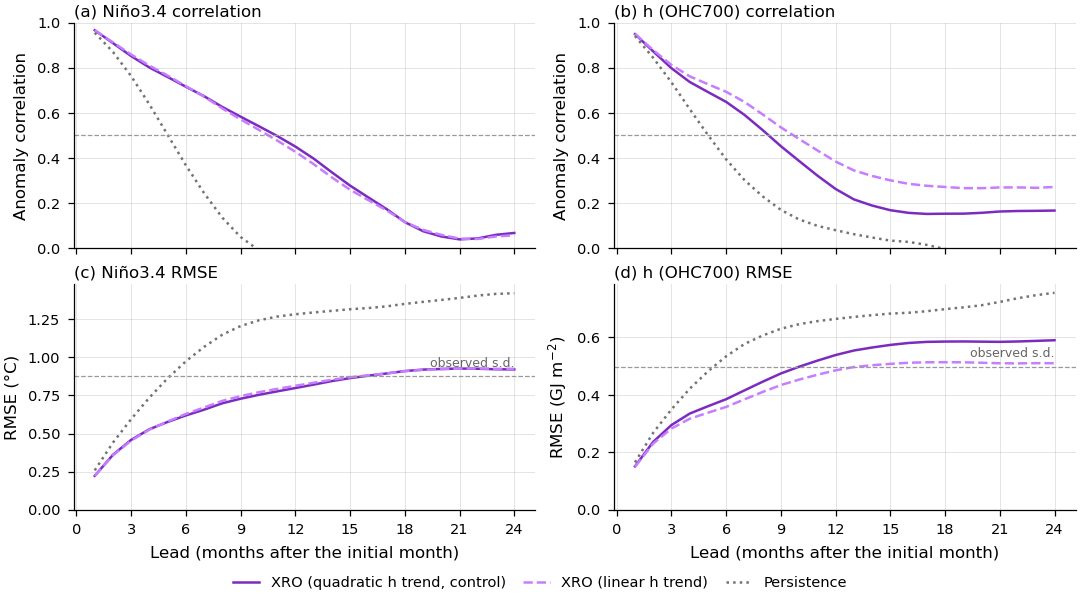

lead                      1     3     6     9     12    18
variable   forecast                                       
Niño3.4    Persistence  0.96  0.76  0.37  0.05 -0.07 -0.17
           linear h     0.97  0.86  0.72  0.57  0.43  0.12
           quadratic h  0.97  0.85  0.72  0.58  0.45  0.12
h (OHC700) Persistence  0.94  0.74  0.39  0.17  0.08  0.00
           linear h     0.95  0.81  0.69  0.54  0.38  0.27
           quadratic h  0.95  0.80  0.65  0.45  0.26  0.15

In [8]:
STYLES = {CONTROL: {"color": COLORS["XRO"], "label": f"XRO ({CONTROL} trend, control)"},
          "linear h": {"color": COLORS["XRO linear h"], "ls": "--", "label": "XRO (linear h trend)"},
          "Persistence": {"color": COLORS["Persistence"], "ls": ":", "label": "Persistence"}}
fig, axes = plt.subplots(2, 2, figsize=(pf.WIDTH["double"], 4.0), sharex=True)
leads = det["lead"].values[1:]
for c, var in enumerate(SKILL_VARS):
    for name, st in STYLES.items():
        sk = SKILL[name][var].isel(lead=slice(1, None))
        axes[0, c].plot(leads, sk["acc"], **st)
        axes[1, c].plot(leads, sk["rmse"], **st)
    axes[0, c].axhline(0.5, color="0.6", lw=0.6, ls="--")
    axes[0, c].set_ylim(0, 1)
    axes[1, c].axhline(obs_sd[var], color="0.6", lw=0.6, ls="--")
    axes[1, c].annotate("observed s.d.", (leads[-1], obs_sd[var]), xytext=(0, 3), textcoords="offset points",
                         va="bottom", ha="right", fontsize=6, color="0.4")
    axes[1, c].set_ylim(0, None)
    axes[0, c].set_ylabel("Anomaly correlation")
    axes[1, c].set_ylabel(f"RMSE ({xc.UNITS[var]})")
    axes[1, c].set_xlabel("Lead (months after the initial month)")
    pf.panel_label(axes[0, c], c, f"{xc.short(var)} correlation")
    pf.panel_label(axes[1, c], 2 + c, f"{xc.short(var)} RMSE")
for ax in axes.flat:
    ax.set_xticks(range(0, VALID["n_month"] + 1, 3))
    ax.grid(True)
pf.legend_below(fig, ax=axes[0, 0], ncol=3)
pf.save(fig, NOTEBOOK, "xro", "oos_skill_by_lead")
plt.show()

rows = []
for name in STYLES:
    for var in SKILL_VARS:
        for L in (1, 3, 6, 9, 12, 18):
            sk = SKILL[name][var].sel(lead=L)
            rows.append({"forecast": name, "variable": xc.short(var), "lead": L, "acc": round(float(sk["acc"]), 2),
                         "rmse": round(float(sk["rmse"]), 2), "n": int(sk["n"])})
skill_summary = pd.DataFrame(rows)
skill_summary.to_csv(OUTDIR / "XRO_oos_skill_summary.csv", index=False)
display(skill_summary.pivot_table(index=["variable", "forecast"], columns="lead", values="acc"))

## 5. Skill by initial month

Correlation skill of Niño3.4 and *h* for the four initial months used for the hindcast starts
(Jan, Apr, Jul, Oct → Feb, May, Aug, Nov starts), against target lead. Low skill through boreal
spring from the Jan initial month is the spring predictability barrier; this is the context for the
Feb-start comparisons with E3SM.

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7a_xro_validation/figures/fig_xro_oos_skill_by_initial_month.pdf
/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7a_xro_validation/figures/fig_xro_oos_skill_by_initial_month.png


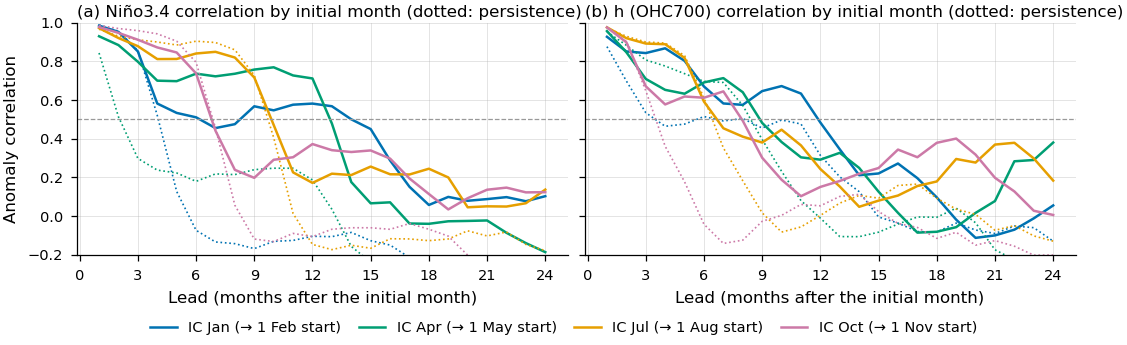

In [9]:
init_month = pd.DatetimeIndex(det["init"].values).month
MONTH_COLORS = {1: "#0072b2", 4: "#009e73", 7: "#e69f00", 10: "#cc79a7"}
fig, axes = plt.subplots(1, 2, figsize=(pf.WIDTH["double"], 2.3), sharey=True)
by_month = {}
for c, var in enumerate(SKILL_VARS):
    for start, ic in START_ICS.items():
        sel = np.flatnonzero(init_month == ic)
        sk = xc.skill(det[var].isel(init=sel), OBS_GRID[var].isel(init=sel))
        pe = xc.skill(xc.persistence(det, OBS_GRID)[var].isel(init=sel), OBS_GRID[var].isel(init=sel))
        by_month[(var, start)] = sk
        axes[c].plot(leads, sk["acc"].isel(lead=slice(1, None)), color=MONTH_COLORS[ic],
                     label=f"IC {xc.MONTH_NAMES[ic]} (→ 1 {xc.MONTH_NAMES[start]} start)")
        axes[c].plot(leads, pe["acc"].isel(lead=slice(1, None)), color=MONTH_COLORS[ic], ls=":", lw=0.8)
    axes[c].axhline(0.5, color="0.6", lw=0.6, ls="--")
    axes[c].set_ylim(-0.2, 1)
    axes[c].set_xticks(range(0, VALID["n_month"] + 1, 3))
    axes[c].set_xlabel("Lead (months after the initial month)")
    axes[c].grid(True)
    pf.panel_label(axes[c], c, f"{xc.short(var)} correlation by initial month (dotted: persistence)")
axes[0].set_ylabel("Anomaly correlation")
pf.legend_below(fig, ax=axes[0], ncol=4)
pf.save(fig, NOTEBOOK, "xro", "oos_skill_by_initial_month")
plt.show()

## 6. Amplitude of the DJF peak

For every year Y of the validation period, the observed DJF (Y/Y+1) Niño3.4 against XRO's
out-of-sample forecast of the same season from the Jan, Apr, Jul and Oct initial months of Y (the
hindcast starts' initial months). The regression slope measures amplitude: a slope below 1 means
XRO forecasts are too weak, as expected of a damped linear-dominated model whose ensemble mean
regresses toward climatology. Bars are the stochastic 5-95% range; strong El Niños (observed
DJF ≥ `STRONG`) are labelled. This tests whether a weaker XRO forecast is itself evidence that
a dynamical model overshoots.

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7a_xro_validation/figures/fig_xro_djf_amplitude.pdf
/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7a_xro_validation/figures/fig_xro_djf_amplitude.png


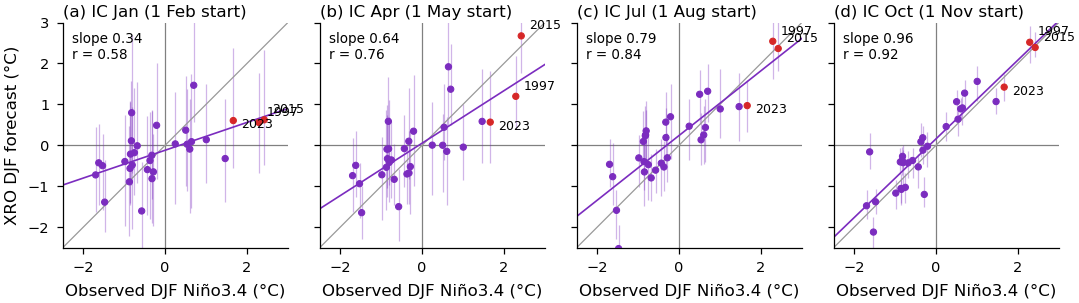

,initial month,slope,r,strong-event mean ratio forecast/observed,strong events inside 5-95%
start,,,,,
Feb,Jan,0.34,0.58,0.29,1/3
May,Apr,0.64,0.76,0.66,2/3
Aug,Jul,0.79,0.84,0.89,2/3
Nov,Oct,0.96,0.92,0.98,3/3


,start,Aug,Feb,May,Nov
year,obs_DJF,,,,
1997,2.291690,2.54,0.56,1.20,2.52
2015,2.424532,2.37,0.62,2.67,2.39
2023,1.666591,0.97,0.60,0.57,1.42


In [10]:
def djf_obs(Y):
    vals = [xc.obs_value(X, "Nino34", *ym) for ym in [(Y, 12), (Y + 1, 1), (Y + 1, 2)]]
    return float(np.mean(vals)) if np.all(np.isfinite(vals)) else np.nan


def djf_forecast(fc, Y, ic):
    """Forecast DJF (Y/Y+1) mean from initial month (Y, ic): leads 12-ic .. 14-ic."""
    i = np.flatnonzero(pd.DatetimeIndex(fc["init"].values) == pd.Timestamp(Y, ic, 1))
    if not i.size:
        return None
    return fc["Nino34"].isel(init=int(i[0])).sel(lead=[12 - ic, 13 - ic, 14 - ic]).mean("lead")


lo, hi = xc.XRO_SETUP["spread"]
amp_rows = []
for Y in range(VALID["years"][0], VALID["years"][1] + 1):
    o = djf_obs(Y)
    for start, ic in START_ICS.items():
        d = djf_forecast(det, Y, ic)
        s = djf_forecast(stoch, Y, ic)
        if d is None or not np.isfinite(o):
            continue
        amp_rows.append({"year": Y, "start": xc.MONTH_NAMES[start], "ic": xc.MONTH_NAMES[ic], "obs_DJF": o,
                         "xro_det": float(d), "xro_lo": float(s.quantile(lo / 100, "member")),
                         "xro_hi": float(s.quantile(hi / 100, "member"))})
amp = pd.DataFrame(amp_rows)

fig, axes = plt.subplots(1, 4, figsize=(pf.WIDTH["double"], 2.25), sharex=True, sharey=True)
amp_stats = []
for k, (ax, (start, ic)) in enumerate(zip(axes, START_ICS.items())):
    a = amp[amp["start"] == xc.MONTH_NAMES[start]]
    strong = a["obs_DJF"] >= STRONG
    ax.errorbar(a["obs_DJF"], a["xro_det"], yerr=[a["xro_det"] - a["xro_lo"], a["xro_hi"] - a["xro_det"]],
                fmt="none", ecolor=COLORS["XRO"], alpha=0.35, lw=0.6)
    ax.scatter(a["obs_DJF"], a["xro_det"], s=9, color=np.where(strong, "#d62728", COLORS["XRO"]), zorder=3)
    for _, r in a[strong].iterrows():
        ax.annotate(f"{r['year']}", (r["obs_DJF"], r["xro_det"]), xytext=(4, -2 + 7 * (r["year"] % 3 - 1)),
                    textcoords="offset points", fontsize=6, ha="left", va="center")
    slope, intercept = np.polyfit(a["obs_DJF"], a["xro_det"], 1)
    r = np.corrcoef(a["obs_DJF"], a["xro_det"])[0, 1]
    lim = np.array([-2.5, 3.0])
    ax.plot(lim, lim, color="0.6", lw=0.6)
    ax.plot(lim, intercept + slope * lim, color=COLORS["XRO"], lw=0.8)
    ax.text(0.04, 0.96, f"slope {slope:.2f}\nr = {r:.2f}", transform=ax.transAxes, va="top", fontsize=6.5)
    ax.set_xlim(*lim)
    ax.set_ylim(*lim)
    ax.set_aspect("equal")
    pf.zero_line(ax)
    pf.zero_line(ax, axis="x")
    ax.set_xlabel("Observed DJF Niño3.4 (°C)")
    pf.panel_label(ax, k, f"IC {xc.MONTH_NAMES[ic]} (1 {xc.MONTH_NAMES[start]} start)")
    amp_stats.append({"start": xc.MONTH_NAMES[start], "initial month": xc.MONTH_NAMES[ic], "slope": round(slope, 2),
                      "r": round(r, 2), "strong-event mean ratio forecast/observed":
                      round(float((a.loc[strong, "xro_det"] / a.loc[strong, "obs_DJF"]).mean()), 2),
                      "strong events inside 5-95%":
                      f"{int(((a.loc[strong, 'obs_DJF'] >= a.loc[strong, 'xro_lo']) & (a.loc[strong, 'obs_DJF'] <= a.loc[strong, 'xro_hi'])).sum())}/{int(strong.sum())}"})
axes[0].set_ylabel("XRO DJF forecast (°C)")
pf.save(fig, NOTEBOOK, "xro", "djf_amplitude")
plt.show()
amp.round(2).to_csv(OUTDIR / "XRO_oos_DJF_forecasts.csv", index=False)
display(pd.DataFrame(amp_stats).set_index("start"))
display(amp[amp["obs_DJF"] >= STRONG].pivot_table(index=["year", "obs_DJF"], columns="start", values="xro_det").round(2))

## 7. Calibration of the stochastic ensemble

A reliable ensemble has (a) spread (mean member standard deviation) close to the RMSE of its
ensemble mean, and (b) the observation inside the 5-95% range about 90% of the time. Spread below
RMSE means the red-noise ensemble is overconfident and its 5-95% bands in 7b-7c understate the
uncertainty.

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7a_xro_validation/figures/fig_xro_stochastic_calibration.pdf
/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7a_xro_validation/figures/fig_xro_stochastic_calibration.png


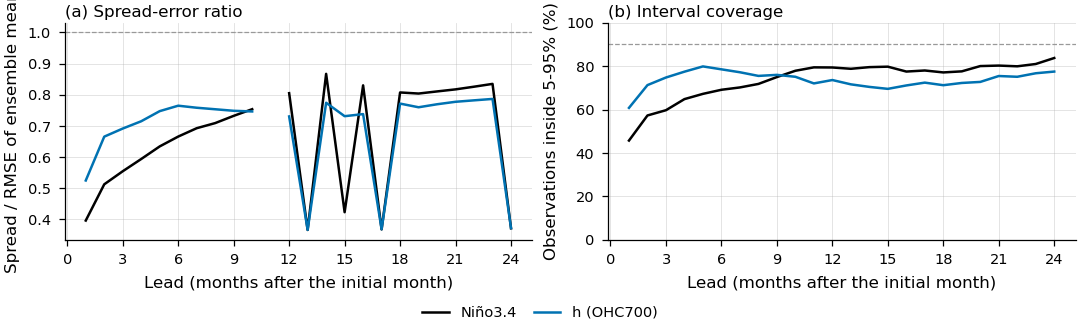

,variable,lead,spread/RMSE,% inside 5-95%
0,Niño3.4,3,0.55,59.7
1,Niño3.4,6,0.67,69.1
2,Niño3.4,12,0.81,79.3
3,h (OHC700),3,0.69,74.7
4,h (OHC700),6,0.76,78.5
5,h (OHC700),12,0.73,73.6


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(pf.WIDTH["double"], 2.2))
calib_rows = []
for c, var in enumerate(SKILL_VARS):
    ens = stoch[var]
    o = OBS_GRID[var]
    ok = o.notnull()
    rmse = np.sqrt(((ens.mean("member") - o) ** 2).where(ok).mean("init"))
    spread = ens.std("member").where(ok).mean("init")
    inside = ((o >= ens.quantile(lo / 100, "member")) & (o <= ens.quantile(hi / 100, "member"))).where(ok).mean("init")
    axes[0].plot(leads, (spread / rmse).isel(lead=slice(1, None)), color=["k", "#0072b2"][c], label=xc.short(var))
    axes[1].plot(leads, 100 * inside.isel(lead=slice(1, None)), color=["k", "#0072b2"][c], label=xc.short(var))
    for L in (3, 6, 12):
        calib_rows.append({"variable": xc.short(var), "lead": L, "spread/RMSE": round(float(spread.sel(lead=L) / rmse.sel(lead=L)), 2),
                           f"% inside {lo}-{hi}%": round(100 * float(inside.sel(lead=L)), 1)})
axes[0].axhline(1.0, color="0.6", lw=0.6, ls="--")
axes[0].set_ylabel("Spread / RMSE of ensemble mean")
axes[1].axhline(hi - lo, color="0.6", lw=0.6, ls="--")
axes[1].set_ylabel(f"Observations inside {lo}-{hi}% (%)")
axes[1].set_ylim(0, 100)
for k, ax in enumerate(axes):
    ax.set_xlabel("Lead (months after the initial month)")
    ax.set_xticks(range(0, VALID["n_month"] + 1, 3))
    ax.grid(True)
pf.panel_label(axes[0], 0, "Spread-error ratio")
pf.panel_label(axes[1], 1, "Interval coverage")
pf.legend_below(fig, ax=axes[0], ncol=2)
pf.save(fig, NOTEBOOK, "xro", "stochastic_calibration")
plt.show()
calib = pd.DataFrame(calib_rows)
calib.to_csv(OUTDIR / "XRO_stochastic_calibration.csv", index=False)
display(calib)

## Summary for the later notebooks

Read the tables above against these questions before using XRO as the benchmark in 7b-7d:

* **Regime (section 2-3):** damped oscillator with a period of a few years, winter phase-locking,
  *h* leading *T* by several months, positive Niño3.4 skewness.
* **Skill (section 4-5):** correlation clearly above persistence beyond about 3 months; the Jan
  initial month (Feb starts) is the weakest.
* **Amplitude (section 6):** the DJF regression slope and the strong-event ratio say how much weaker
  than observed a skilful XRO forecast typically is. An E3SM-minus-XRO difference of that size or
  smaller is not evidence that E3SM overshoots.
* **Uncertainty (section 7):** if spread/RMSE < 1, widen the reading of XRO's 5-95% bands.
* **Detrending (section 4):** if linear and quadratic *h* trends give clearly different skill, the
  event forecasts in 7b should be shown for both.